Manual TP/FP/TN/FN derivation; ROC+PR curves for LR/RF/XGB; Platt scaling calibration; McNemar's test; model_evaluation_report()
function

Models trained successfully.

MANUAL CONFUSION COUNTS
LR {'TP': 89, 'FP': 5, 'TN': 48, 'FN': 1}
RF {'TP': 88, 'FP': 4, 'TN': 49, 'FN': 2}
XGB {'TP': 88, 'FP': 4, 'TN': 49, 'FN': 2}

SKLEARN CONFUSION MATRICES
LR
[[48  5]
 [ 1 89]]
RF
[[49  4]
 [ 2 88]]
XGB
[[49  4]
 [ 2 88]]


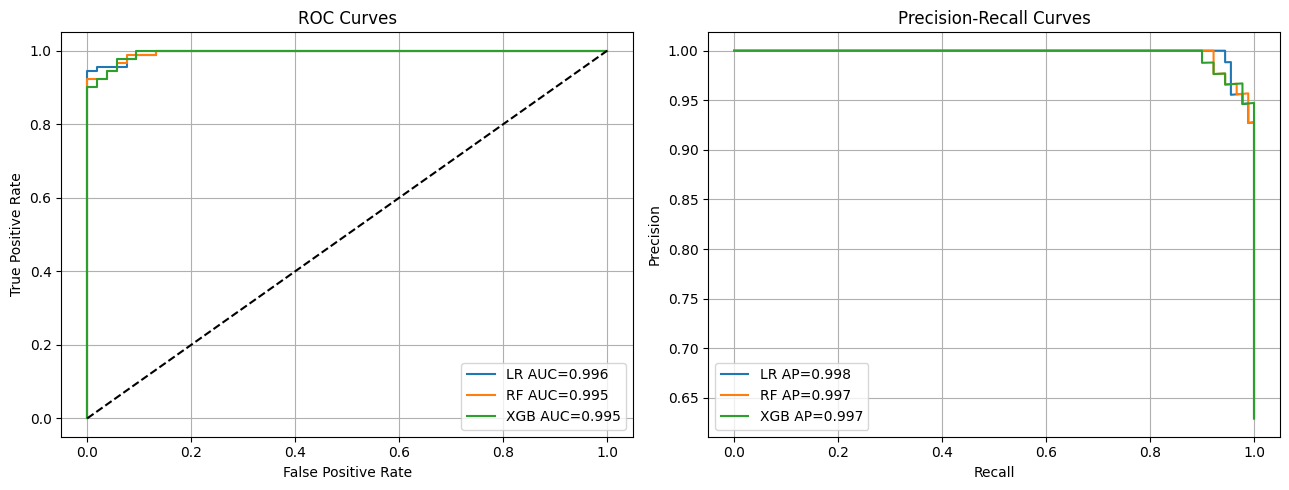

<Figure size 700x600 with 0 Axes>

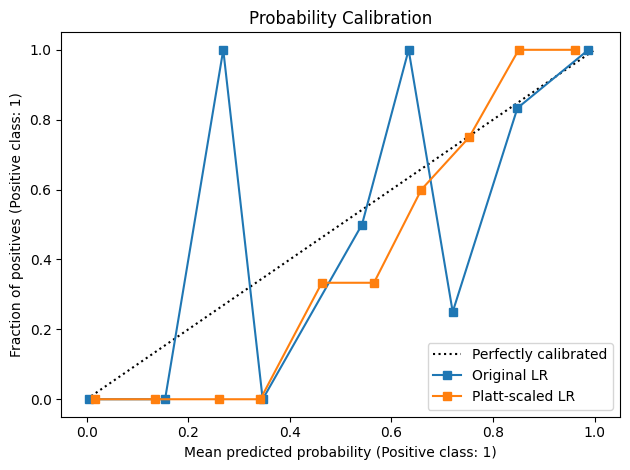


McNEMAR TEST: LR VS RF
{'A_correct_B_wrong': 2, 'A_wrong_B_correct': 2, 'p_value': 1.0}
No statistically significant difference at the 0.05 level.

MODEL EVALUATION REPORT
Model  Accuracy  Precision  Recall     F1  ROC_AUC  PR_Average_Precision  TP  FP  TN  FN
   LR     0.958     0.9468  0.9889 0.9674   0.9956                0.9975  89   5  48   1
   RF     0.958     0.9565  0.9778 0.9670   0.9948                0.9970  88   4  49   2
  XGB     0.958     0.9565  0.9778 0.9670   0.9948                0.9969  88   4  49   2

All evaluation tasks completed successfully!


In [1]:

# Install XGBoost
!pip -q install xgboost

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score
)
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.base import clone
from scipy.stats import binomtest


# ==========================================================
# 1. LOAD DATA AND TRAIN LR, RF, XGB
# ==========================================================

data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

models = {
    "LR": LogisticRegression(max_iter=5000),
    "RF": RandomForestClassifier(
        n_estimators=150, random_state=42
    ),
    "XGB": XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.05,
        eval_metric="logloss",
        random_state=42,
        n_jobs=2
    )
}

predictions = {}
probabilities = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    probabilities[name] = model.predict_proba(X_test)[:, 1]

print("Models trained successfully.")


# ==========================================================
# 2. MANUAL TP, FP, TN, FN DERIVATION
# ==========================================================

def manual_confusion_counts(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    TP = int(np.sum((y_true == 1) & (y_pred == 1)))
    FP = int(np.sum((y_true == 0) & (y_pred == 1)))
    TN = int(np.sum((y_true == 0) & (y_pred == 0)))
    FN = int(np.sum((y_true == 1) & (y_pred == 0)))

    return {"TP": TP, "FP": FP, "TN": TN, "FN": FN}


print("\nMANUAL CONFUSION COUNTS")
for name, pred in predictions.items():
    counts = manual_confusion_counts(y_test, pred)
    print(name, counts)

# Check the counts against sklearn
print("\nSKLEARN CONFUSION MATRICES")
for name, pred in predictions.items():
    print(name)
    print(confusion_matrix(y_test, pred))


# ==========================================================
# 3. ROC AND PRECISION-RECALL CURVES
# ==========================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)

    axes[0].plot(fpr, tpr, label=f"{name} AUC={auc:.3f}")

    precision, recall, _ = precision_recall_curve(y_test, prob)
    ap = average_precision_score(y_test, prob)

    axes[1].plot(recall, precision, label=f"{name} AP={ap:.3f}")

axes[0].plot([0, 1], [0, 1], "k--")
axes[0].set_title("ROC Curves")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()
axes[0].grid(True)

axes[1].set_title("Precision-Recall Curves")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


# ==========================================================
# 4. PLATT SCALING CALIBRATION
# ==========================================================

# Fit calibration using training data only.
# The test set remains unseen during calibration.
base_lr = LogisticRegression(max_iter=5000)

calibrated_lr = CalibratedClassifierCV(
    estimator=clone(base_lr),
    method="sigmoid",
    cv=5
)

calibrated_lr.fit(X_train, y_train)

calibrated_prob = calibrated_lr.predict_proba(X_test)[:, 1]

plt.figure(figsize=(7, 6))

CalibrationDisplay.from_predictions(
    y_test,
    probabilities["LR"],
    n_bins=10,
    name="Original LR"
)

CalibrationDisplay.from_predictions(
    y_test,
    calibrated_prob,
    n_bins=10,
    name="Platt-scaled LR",
    ax=plt.gca()
)

plt.title("Probability Calibration")
plt.tight_layout()
plt.show()


# ==========================================================
# 5. McNEMAR'S TEST: COMPARE LR AND RF
# ==========================================================

def mcnemar_test(y_true, pred_a, pred_b):
    y_true = np.asarray(y_true)
    pred_a = np.asarray(pred_a)
    pred_b = np.asarray(pred_b)

    # b: A correct, B incorrect
    b = int(np.sum(
        (pred_a == y_true) & (pred_b != y_true)
    ))

    # c: A incorrect, B correct
    c = int(np.sum(
        (pred_a != y_true) & (pred_b == y_true)
    ))

    # Exact two-sided binomial test on discordant pairs
    if b + c == 0:
        p_value = 1.0
    else:
        p_value = binomtest(
            min(b, c),
            n=b + c,
            p=0.5,
            alternative="two-sided"
        ).pvalue

    return {
        "A_correct_B_wrong": b,
        "A_wrong_B_correct": c,
        "p_value": float(p_value)
    }


mcnemar_result = mcnemar_test(
    y_test, predictions["LR"], predictions["RF"]
)

print("\nMcNEMAR TEST: LR VS RF")
print(mcnemar_result)

if mcnemar_result["p_value"] < 0.05:
    print("Significant difference at the 0.05 level.")
else:
    print("No statistically significant difference at the 0.05 level.")


# ==========================================================
# 6. model_evaluation_report() FUNCTION
# ==========================================================

def model_evaluation_report(models, X_train, X_test, y_train, y_test):
    rows = []
    fitted_models = {}
    prediction_dict = {}
    probability_dict = {}

    for name, estimator in models.items():
        model = clone(estimator)
        model.fit(X_train, y_train)

        pred = model.predict(X_test)
        prob = model.predict_proba(X_test)[:, 1]

        counts = manual_confusion_counts(y_test, pred)

        rows.append({
            "Model": name,
            "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred, zero_division=0),
            "F1": f1_score(y_test, pred, zero_division=0),
            "ROC_AUC": roc_auc_score(y_test, prob),
            "PR_Average_Precision": average_precision_score(y_test, prob),
            **counts
        })

        fitted_models[name] = model
        prediction_dict[name] = pred
        probability_dict[name] = prob

    report_df = pd.DataFrame(rows).round(4)

    return {
        "metrics": report_df,
        "models": fitted_models,
        "predictions": prediction_dict,
        "probabilities": probability_dict
    }


# Run the evaluation report
report = model_evaluation_report(
    models, X_train, X_test, y_train, y_test
)

print("\nMODEL EVALUATION REPORT")
print(report["metrics"].to_string(index=False))

print("\nAll evaluation tasks completed successfully!")


Write full_cv_report(estimator, X, y, param_grid, outer_k=5, inner_k=3) — returns dict [stratified_kfold_mean, std, nested_cv_mean,
non_nested_best, optimism_bias]

In [ ]:

import numpy as np
from sklearn.base import clone
from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    cross_val_score
)

def full_cv_report(estimator, X, y, param_grid,
                   outer_k=5, inner_k=3):

    # Stratified K-Fold evaluation
    outer_cv = StratifiedKFold(
        n_splits=outer_k,
        shuffle=True,
        random_state=42
    )

    stratified_scores = cross_val_score(
        clone(estimator), X, y,
        cv=outer_cv,
        scoring="accuracy"
    )

    stratified_kfold_mean = float(np.mean(stratified_scores))
    stratified_kfold_std = float(np.std(stratified_scores))

    # Inner CV for hyperparameter tuning
    inner_cv = StratifiedKFold(
        n_splits=inner_k,
        shuffle=True,
        random_state=42
    )

    grid = GridSearchCV(
        clone(estimator),
        param_grid,
        cv=inner_cv,
        scoring="accuracy",
        n_jobs=-1
    )

    # Non-nested best score
    grid.fit(X, y)
    non_nested_best = float(grid.best_score_)

    # Nested cross-validation
    nested_grid = GridSearchCV(
        clone(estimator),
        param_grid,
        cv=inner_cv,
        scoring="accuracy",
        n_jobs=-1
    )

    nested_scores = cross_val_score(
        nested_grid,
        X, y,
        cv=outer_cv,
        scoring="accuracy"
    )

    nested_cv_mean = float(np.mean(nested_scores))

    # Estimated optimism bias
    optimism_bias = non_nested_best - nested_cv_mean

    return {
        "stratified_kfold_mean": stratified_kfold_mean,
        "stratified_kfold_std": stratified_kfold_std,
        "nested_cv_mean": nested_cv_mean,
        "non_nested_best": non_nested_best,
        "optimism_bias": float(optimism_bias)
    }


# Example execution
from sklearn.datasets import load_breast_cancer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

data = load_breast_cancer()
X, y = data.data, data.target

# Pipeline prevents scaling leakage
estimator = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000))
])

param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

report = full_cv_report(
    estimator, X, y, param_grid,
    outer_k=5, inner_k=3
)

print("Full CV Report:")
for key, value in report.items():
    print(f"{key}: {value:.4f}")


Full CV Report:
stratified_kfold_mean: 0.9737
stratified_kfold_std: 0.0166
nested_cv_mean: 0.9737
non_nested_best: 0.9754
optimism_bias: 0.0018
